# Prototipo final · Riesgo de no renovación de membresías (Mtabolic)

**Notebook oficial de la entrega final** (antes se llamaba `MVP_simple.ipynb`). Es una versión corta y comentada de `MVP.ipynb` que hace **lo mismo que la aplicación**: mismo corte T−30, mismas 8 variables, mismo Random Forest (el modelo adoptado), mismos niveles y mismos motivos SHAP.

**Versión 2 (2026-11-02).** Incorpora las correcciones de la evaluación de la semana 10. El detalle y las cifras están en `Documentation/mejoras/M05-correcciones-evaluacion-semana-10.md`.

| Corrección | Qué cambió en este notebook |
|---|---|
| NC1 · Cronología | Partición con márgenes de **más de 60 días**: cada etiqueta (T+30) se conoce antes de la primera predicción (T−30) del conjunto siguiente. Una tabla y un `assert` lo comprueban (Parte 6). |
| NC2 · Métodos | Bootstrap **por socio**, SHAP con `TreeExplainer` (aditividad comprobada) y códigos HMAC-SHA256 con clave secreta (ya estaban; se documentan). |
| NC4 · Cifras | Tabla 10 con la comparación RF − RL; cifras para el informe en la Parte 12; tablas exportadas en la Parte 13. |
| NC3 · Reproducibilidad | Versiones de Python y librerías y huella SHA-256 de los Excel impresas en la salida; `requirements.txt` en la raíz del proyecto. |

**Modelo adoptado: Random Forest (desviación explícita de la regla).** Con la partición corregida, los dos modelos cumplen los tres criterios en validación y la regla fijada de antemano (gana el de mayor PR-AUC) elige la Regresión Logística por 0,017 de PR-AUC, una diferencia que el bootstrap por socio no distingue del azar. El equipo **adopta el Random Forest**, que es el modelo integrado y verificado en la aplicación (lista, motivos SHAP, pruebas y paridad con este notebook), y lo reporta como desviación de la regla. Las métricas de los dos modelos se muestran siempre; la Regresión Logística queda como alternativa para la siguiente versión (ver M05).

**Cómo usarlo**
1. Python 3.12 y las librerías del `requirements.txt` de la raíz del proyecto (`pip install -r requirements.txt`, desde la raíz). Las versiones exactas importan: con otra versión de scikit-learn el bosque cambia.
2. Los libros `Control Gym 2025*.xlsx` y `Control Gym 2026*.xlsx` deben estar en la carpeta `plantillas/` del proyecto (o en la carpeta indicada en la variable de entorno `MTABOLIC_DATOS`).
3. Abrir el notebook desde la carpeta `Notebookes/` y ejecutar **Run → Run All Cells**. Tarda alrededor de un minuto.
4. La **Parte 11 · Controles** debe terminar con «TODOS LOS CONTROLES OK». La **Parte 13** guarda las tablas, los modelos y la lista de referencia con que `Backend/scripts/verificar_lista.py` compara la app, en `salidas/prototipo_final/`.

**Mapa: qué parte del notebook equivale a qué parte de la app**

| Parte | Qué hace | Dónde está en la app (`Backend/app/...`) |
|---|---|---|
| 2 | Leer las hojas mensuales | `infrastructure/historico/lector_libros.py` |
| 3 | Limpiar identidad, plan y fechas | `domain/historico/normalizacion.py` |
| 4 | Estado del ciclo y etiqueta T+30 | `domain/historico/ciclos.py` |
| 5 | Variables en T−30 | `domain/modelo/variables.py` |
| 6 | Partición con márgenes y medianas de entrenamiento | `domain/modelo/reentrenamiento.py` (la app reentrena con margen de 30 días; ver limitación en M05) |
| 7 | Pipeline y Random Forest | `infrastructure/ml/random_forest.py` |
| 10 | Niveles 0,70 / 0,50 y motivos SHAP | `domain/modelo/umbrales.py` y `random_forest.py` |

Ningún resultado muestra nombres ni cédulas: los socios se identifican con un **código seudónimo** (`MTB-XXXXXXXX`).


## Parte 1 · Configuración
Librerías y **parámetros del negocio**. Todos los números fijos del proyecto están aquí, en un solo lugar.

In [1]:
# --- Librerías estándar ---
import os, re, sys, json, hmac, hashlib, secrets, unicodedata, warnings
from pathlib import Path
from datetime import datetime
import joblib

# --- Análisis de datos ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# --- Aprendizaje automático ---
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
                             average_precision_score, roc_auc_score, brier_score_loss)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    import shap                                   # explicabilidad (valores SHAP)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", None)

# Las versiones deben ser las mismas que usa la app; con otras versiones las cifras pueden cambiar
print("Python", sys.version.split()[0], "| scikit-learn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__, "| shap", shap.__version__)
assert sklearn.__version__ == "1.8.0" and shap.__version__ == "0.54.1", "Instalar scikit-learn==1.8.0 y shap==0.54.1"

Python 3.12.16 | scikit-learn 1.8.0 | numpy 2.5.3 | pandas 3.0.6 | shap 0.54.1


In [2]:
# ===================== PARÁMETROS DEL NEGOCIO (iguales a la app) =====================
SEMILLA = 42                      # número fijo: todo lo aleatorio se repite igual en cada ejecución
DIAS_ANTES_PREDICCION = 30        # T−30: la lista se genera 30 días antes del vencimiento
DIAS_OBSERVACION = 30             # T+30: se espera 30 días después del vencimiento para saber si renovó
TOP_K = 25                        # capacidad de contacto: socios que se llaman primero cada mes
FECHA_MINIMA_RAZONABLE = pd.Timestamp("2024-12-01")   # vencimientos anteriores se consideran error de digitación
DURACION_MIN, DURACION_MAX = 21, 400                  # duraciones fuera de este rango son imposibles

# Partición por fecha de vencimiento (corrección NC1 de la evaluación de la semana 10).
# Regla: la última etiqueta de un conjunto (su vencimiento más tardío + 30 días = T+30) debe conocerse
# ANTES de la primera predicción del conjunto siguiente (su vencimiento más temprano − 30 días = T−30).
# Eso exige más de 60 días entre el último vencimiento de un conjunto y el primero del siguiente.
FIN_ENTRENAMIENTO = pd.Timestamp("2025-10-31")    # entrenamiento: vencimientos hasta el 31-10-2025
INICIO_VALIDACION = pd.Timestamp("2026-01-01")    # validación: del 01-01-2026 ...
FIN_VALIDACION = pd.Timestamp("2026-03-01")       # ... al 01-03-2026
INICIO_PRUEBA = pd.Timestamp("2026-05-01")        # prueba: desde el 01-05-2026 (los mismos 277 casos de la versión anterior)

# Las 8 variables del modelo (sin forma de pago ni fecha de inicio aproximada, decisión M01)
VARIABLES_NUMERICAS = ["ciclos_previos", "antiguedad_dias", "duracion_modelo",
                       "monto_actual", "monto_historico", "dias_desde_ultima_membresia"]
VARIABLES_CATEGORICAS = ["plan", "mes_vencimiento"]
VARIABLES_MODELO = VARIABLES_NUMERICAS + VARIABLES_CATEGORICAS

# Random Forest: mismos hiperparámetros que la app (fijados antes de ver resultados, sin búsqueda)
HIPERPARAMETROS_RF = dict(n_estimators=300, max_depth=6, min_samples_leaf=20,
                          class_weight="balanced", random_state=SEMILLA)

# Modelo adoptado (decisión del equipo, M05): el Random Forest, el que usa la app para la lista y los
# motivos SHAP. La regla de selección se aplica y se reporta igual (Parte 7): si elige otro modelo, la
# diferencia se documenta como desviación de la regla.
MODELO_ADOPTADO = "Random Forest"
MODELO_PRODUCTO = MODELO_ADOPTADO

# Niveles de riesgo de la app: ALTO si score >= 0,70; MEDIO si >= 0,50; si no, BAJO
UMBRAL_ALTO, UMBRAL_MEDIO = 0.70, 0.50
DURACION_ESTANDAR = {"MENSUAL": 30, "TRIMESTRAL": 90, "SEMESTRAL": 180, "ANUAL": 365, "OTRO": 30}

In [3]:
# Carpeta de los libros de Excel: variable de entorno MTABOLIC_DATOS o, por defecto, ../plantillas
CARPETA_DATOS = Path(os.environ.get("MTABOLIC_DATOS", Path("..") / "plantillas"))

def buscar_archivo(anio):
    candidatos = sorted(CARPETA_DATOS.glob(f"*Control*Gym*{anio}*.xlsx"))
    if not candidatos:
        raise FileNotFoundError(f"No se encontró el libro {anio} en {CARPETA_DATOS}")
    return candidatos[0]

archivo_2025, archivo_2026 = buscar_archivo(2025), buscar_archivo(2026)
print("Libros encontrados:", archivo_2025.name, "|", archivo_2026.name)

# Huella SHA-256 de los libros usados: demuestra con qué archivos exactos se obtuvieron las cifras.
def huella(ruta):
    return hashlib.sha256(Path(ruta).read_bytes()).hexdigest()[:16]
HUELLAS = {archivo_2025.name: huella(archivo_2025), archivo_2026.name: huella(archivo_2026)}
print("Huella SHA-256 de los libros (16 primeros caracteres):", HUELLAS)

# Código SEUDÓNIMO del socio: HMAC-SHA256 con una clave secreta (en el proyecto se llama «sal»: variable
# MTABOLIC_SAL_CODIGOS o archivo salidas/.sal_codigos, ambos fuera de git; es la misma clave que usa la app).
# Es seudonimización, no anonimato: quien tenga la clave puede volver a vincular un código con su cédula.
# Sin la clave no es posible hacerlo. La clave nunca se imprime.
ARCHIVO_SAL = Path("..") / "salidas" / ".sal_codigos"
SAL = os.environ.get("MTABOLIC_SAL_CODIGOS", "").strip()
if not SAL and ARCHIVO_SAL.is_file():
    SAL = ARCHIVO_SAL.read_text(encoding="utf-8").strip()
if not SAL:
    SAL = secrets.token_hex(32)
    ARCHIVO_SAL.parent.mkdir(parents=True, exist_ok=True)
    ARCHIVO_SAL.write_text(SAL, encoding="utf-8")

def codigo_socio(socio_id):
    return "MTB-" + hmac.new(SAL.encode(), str(socio_id).encode(), hashlib.sha256).hexdigest()[:8].upper()

Libros encontrados: Control Gym 2025 (1).xlsx | Control Gym 2026 (2).xlsx
Huella SHA-256 de los libros (16 primeros caracteres): {'Control Gym 2025 (1).xlsx': '7ad9e21de2dd5f15', 'Control Gym 2026 (2).xlsx': '516600703c316ca1'}


## Parte 2 · Leer los libros de Excel
Cada libro tiene muchas hojas (diarias, novedades, horas extras…). Solo se usan las **20 hojas mensuales** (ENERO…AGOSTO). En cada hoja se busca la fila de títulos y se identifica cada columna aunque cambie de nombre o de posición.

In [4]:
MESES = {"ENERO": 1, "FEBRERO": 2, "MARZO": 3, "ABRIL": 4, "MAYO": 5, "JUNIO": 6, "JULIO": 7,
         "AGOSTO": 8, "SEPTIEMBRE": 9, "OCTUBRE": 10, "NOVIEMBRE": 11, "DICIEMBRE": 12}

# Nombres posibles de cada columna en los Excel (ya en mayúsculas y sin tildes)
ALIAS_COLUMNAS = {
    "nombre":        ["NOMBRES Y APELLIDOS", "NOMBRES Y APELLIDOS DEL SOCIO"],
    "cedula":        ["CEDULA"],
    "plan":          ["TIPO DE PLAN"],
    "fecha_inicio":  ["FECHA INSCRIPCION", "FECHA INICIO"],
    "fecha_fin":     ["FECHA FIN PLAN", "FECHA FIN"],
    "monto_cobrado": ["MONTO A COBRAR", "MONTO COBRAR"],
}

def texto_normalizado(valor):
    # " Cédula  " -> "CEDULA": mayúsculas, sin tildes y con espacios simples
    if pd.isna(valor):
        return ""
    texto = unicodedata.normalize("NFKD", str(valor).strip().upper()).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", texto)

def leer_hoja_mensual(ruta, hoja, anio):
    tabla = pd.read_excel(ruta, sheet_name=hoja, header=None)
    # 1) La fila de títulos es la primera (de las 10 primeras) que contiene "CEDULA" y "NOMBRE"
    fila_titulos = next(i for i in range(min(10, len(tabla)))
                        if "CEDULA" in " | ".join(map(texto_normalizado, tabla.iloc[i]))
                        and "NOMBRE" in " | ".join(map(texto_normalizado, tabla.iloc[i])))
    titulos = [texto_normalizado(v) for v in tabla.iloc[fila_titulos]]
    datos = tabla.iloc[fila_titulos + 1:]
    salida = pd.DataFrame(index=datos.index)
    # 2) Para cada campo, la primera columna cuyo título contiene alguno de sus alias
    for campo, alias in ALIAS_COLUMNAS.items():
        indice = next((i for i, t in enumerate(titulos) if any(a in t for a in alias)), None)
        salida[campo] = datos.iloc[:, indice] if indice is not None else np.nan
    salida["mes_hoja"] = pd.Timestamp(anio, MESES[hoja.strip().upper()], 1)   # primer día del mes de la hoja
    return salida

tablas = []
for ruta, anio in [(archivo_2025, 2025), (archivo_2026, 2026)]:
    for hoja in pd.ExcelFile(ruta).sheet_names:
        if hoja.strip().upper() in MESES:            # solo hojas mensuales
            tablas.append(leer_hoja_mensual(ruta, hoja, anio))
crudo = pd.concat(tablas, ignore_index=True)
print("Hojas mensuales leídas:", len(tablas), "| filas leídas (con vacías y totales):", len(crudo))

Hojas mensuales leídas: 20 | filas leídas (con vacías y totales): 7769


## Parte 3 · Limpiar: filas útiles, identidad del socio, fechas y plan
- Se descartan filas vacías, de totales y títulos repetidos.
- **Identidad del socio:** la cédula (solo dígitos, 9 o más); si no hay, el nombre normalizado. Así se unen todas las membresías de una misma persona.
- Las fechas y montos escritos de distintas formas se convierten a un formato único.
- El plan, escrito de **281 formas**, se reduce a 6 categorías.

In [5]:
# --- 3.1 Filas útiles ---
nombre = crudo["nombre"].astype("string").fillna("").str.strip()
es_util = (nombre.ne("")
           & ~nombre.str.upper().str.contains("TOTAL|SUBTOTAL|SUMA|MONTO", regex=True)
           & ~nombre.str.upper().isin(["STATUS", "NOMBRES Y APELLIDOS", "NOMBRES Y APELLIDOS DEL SOCIO"]))
datos = crudo.loc[es_util].copy()
print("Filas útiles (registros de socios):", len(datos))

# --- 3.2 Conversión de fechas y montos ---
def convertir_fecha(valor):
    if pd.isna(valor):
        return pd.NaT
    if isinstance(valor, (pd.Timestamp, datetime)):
        return pd.Timestamp(valor).normalize()
    if isinstance(valor, (int, float)) and not isinstance(valor, bool):
        if 20000 <= float(valor) <= 60000:                  # número interno de Excel
            return (pd.Timestamp("1899-12-30") + pd.to_timedelta(float(valor), unit="D")).normalize()
    texto = str(valor).strip()
    if not texto:
        return pd.NaT
    fecha = pd.to_datetime(texto, errors="coerce", dayfirst=True)
    if pd.isna(fecha):
        fecha = pd.to_datetime(texto, errors="coerce", dayfirst=False)
    return fecha.normalize() if not pd.isna(fecha) else pd.NaT

def convertir_numero(valor):
    if pd.isna(valor):
        return np.nan
    if isinstance(valor, (int, float)) and not isinstance(valor, bool):
        return float(valor)
    hallado = re.search(r"-?\d+(?:\.\d+)?", str(valor).replace(",", "."))   # "39,50 USD" -> 39.5
    return float(hallado.group(0)) if hallado else np.nan

datos["fecha_inicio"] = datos["fecha_inicio"].apply(convertir_fecha)
datos["fecha_fin"] = datos["fecha_fin"].apply(convertir_fecha)            # fecha_fin = T (vencimiento)
datos["monto_cobrado"] = datos["monto_cobrado"].apply(convertir_numero)
datos["plan_crudo"] = datos["plan"].fillna("").astype(str).str.strip().str.upper()

# --- 3.3 Identidad del socio ---
def normalizar_nombre(texto):
    texto = unicodedata.normalize("NFKD", "" if pd.isna(texto) else str(texto)).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", re.sub(r"[^A-Z ]", " ", texto.upper())).strip()

def normalizar_cedula(valor):
    digitos = "" if pd.isna(valor) else re.sub(r"\D", "", str(valor))
    return digitos if len(digitos) >= 9 else np.nan

datos["nombre_normalizado"] = datos["nombre"].apply(normalizar_nombre)
datos = datos.loc[datos["nombre_normalizado"].str.len() >= 5].copy()      # identidad utilizable
cedula = datos["cedula"].apply(normalizar_cedula)
datos["socio_id"] = np.where(cedula.notna(), "C:" + cedula.fillna(""), "N:" + datos["nombre_normalizado"])
print("Registros con identidad:", len(datos), "| socios distintos:", datos["socio_id"].nunique())

# --- 3.4 Duración y plan normalizado ---
datos["duracion_dias"] = (datos["fecha_fin"] - datos["fecha_inicio"]).dt.days
FORMAS_PAGO_EN_CAMPO_PLAN = ("DATAFAST", "TRANSF", "EFECTIVO", "TARJETA", "DEPOSITO")

def normalizar_plan(texto, duracion):
    texto = str(texto or "").upper().strip()
    if any(p in texto for p in FORMAS_PAGO_EN_CAMPO_PLAN):   # el campo traía una forma de pago, no un plan
        texto = ""
    if "DIARIO" in texto: return "DIARIO"
    if "ANUAL" in texto or "AÑO" in texto or "ANO" in texto: return "ANUAL"
    if "SEMESTR" in texto or "6 MES" in texto: return "SEMESTRAL"
    if any(x in texto for x in ("3 MES", "TRES MES", "TRIMEST")): return "TRIMESTRAL"
    if "MENSUAL" in texto or re.search(r"\b1\s*MES\b", texto) or "PLAN MES" in texto: return "MENSUAL"
    if pd.notna(duracion):                                   # sin palabra clave: se usa la duración
        if 21 <= duracion <= 45: return "MENSUAL"
        if 80 <= duracion <= 130: return "TRIMESTRAL"
        if 160 <= duracion <= 200: return "SEMESTRAL"
        if 330 <= duracion <= 400: return "ANUAL"
    return "OTRO"

datos["plan"] = [normalizar_plan(t, d) for t, d in zip(datos["plan_crudo"], datos["duracion_dias"])]
print("Escrituras distintas del plan:", datos["plan_crudo"].nunique(), "-> categorías:", sorted(datos["plan"].unique()))

Filas útiles (registros de socios): 2771
Registros con identidad: 2748 | socios distintos: 1410
Escrituras distintas del plan: 281 -> categorías: ['ANUAL', 'DIARIO', 'MENSUAL', 'OTRO', 'SEMESTRAL', 'TRIMESTRAL']


## Parte 4 · Estado de cada membresía y etiqueta (¿renovó entre T y T+30?)
- **Fecha de corte:** último día del último mes con datos (31-08-2026).
- Cada membresía queda **evaluable**, **pendiente** (aún no pasan 30 días desde su vencimiento) o **excluida** (con su motivo).
- **Etiqueta `no_renovo`:** 1 si el socio no registró otra membresía (que no sea pase diario) con fecha de actividad entre T y T+30; 0 si sí.
- **Fecha de actividad:** la fecha de inicio o, si falta, el primer día del mes de la hoja.

In [6]:
fecha_corte = datos["mes_hoja"].max() + pd.offsets.MonthEnd(0)
datos["fecha_limite_observacion"] = datos["fecha_fin"] + pd.Timedelta(days=DIAS_OBSERVACION)   # T+30
datos["fecha_prediccion"] = datos["fecha_fin"] - pd.Timedelta(days=DIAS_ANTES_PREDICCION)       # T−30
datos["fecha_actividad"] = datos["fecha_inicio"].fillna(datos["mes_hoja"])
datos["mes_vencimiento"] = datos["fecha_fin"].dt.to_period("M").astype("string")
print("Fecha de corte de los datos:", fecha_corte.date())

def estado_ciclo(f):
    # Las reglas se aplican en este orden; gana la primera que se cumple (igual que la app)
    if pd.isna(f["fecha_fin"]):                     return "EXCLUIDO - Sin fecha de vencimiento"
    if f["fecha_fin"] < FECHA_MINIMA_RAZONABLE:     return "EXCLUIDO - Fecha fuera de rango"
    if f["fecha_fin"] > fecha_corte:                return "EXCLUIDO - Vencimiento posterior al período disponible"
    if f["plan"] == "DIARIO":                       return "EXCLUIDO - Pase diario"
    if pd.notna(f["duracion_dias"]) and (f["duracion_dias"] <= DURACION_MIN or f["duracion_dias"] > DURACION_MAX):
        return "EXCLUIDO - Duración implausible"
    if f["fecha_limite_observacion"] > fecha_corte: return "PENDIENTE - Ventana T+30 incompleta"
    return "EVALUABLE"

datos["estado_ciclo"] = datos.apply(estado_ciclo, axis=1)

# Etiqueta: buscar otra membresía del mismo socio entre T y T+30
membresias = datos.loc[datos["plan"].ne("DIARIO") & datos["fecha_actividad"].notna()]
actividades_por_socio = {s: g.sort_values("fecha_actividad") for s, g in membresias.groupby("socio_id")}

def renovo(fila):
    h = actividades_por_socio.get(fila["socio_id"])
    if h is None:
        return False
    en_ventana = ((h.index != fila.name) & (h["fecha_actividad"] >= fila["fecha_fin"])
                  & (h["fecha_actividad"] <= fila["fecha_limite_observacion"]))
    return bool(en_ventana.any())

evaluable = datos["estado_ciclo"].eq("EVALUABLE")
datos["no_renovo"] = np.nan
datos.loc[evaluable, "no_renovo"] = [0 if renovo(f) else 1 for _, f in datos.loc[evaluable].iterrows()]

display(datos["estado_ciclo"].value_counts().rename_axis("estado").reset_index(name="registros"))
n_eval, n_nr = int(evaluable.sum()), int((datos["no_renovo"] == 1).sum())
print(f"Membresías evaluables: {n_eval} | no renovaron: {n_nr} ({100 * n_nr / n_eval:.1f} %)")

Fecha de corte de los datos: 2026-08-31


,estado,registros
0,EVALUABLE,1564
1,EXCLUIDO - Sin fecha de vencimiento,855
2,EXCLUIDO - Vencimiento posterior al período disponible,160
3,PENDIENTE - Ventana T+30 incompleta,96
4,EXCLUIDO - Duración implausible,49
5,EXCLUIDO - Pase diario,16
6,EXCLUIDO - Fecha fuera de rango,8


Membresías evaluables: 1564 | no renovaron: 1098 (70.2 %)


## Parte 5 · Las variables que ve el modelo (solo información hasta T−30)
Para cada membresía, su **historial admitido** son las otras membresías no excluidas del mismo socio con fecha de actividad **anterior** a la del ciclo **y menor o igual a T−30**. Lo que pasa después de T−30 no existe para el modelo: así se evita la **fuga de información**.

In [7]:
# Membresías con calidad suficiente (evaluables + pendientes), ordenadas por socio y fecha.
# El orden importa: el Random Forest sortea filas y con otro orden los resultados cambian ligeramente.
modelables = (datos.loc[~datos["estado_ciclo"].str.startswith("EXCLUIDO")]
              .sort_values(["socio_id", "fecha_actividad", "fecha_fin"]).copy())

def variables_historicas(fila, historial, corte_t30=True):
    # Historial admitido: otras membresías del socio, anteriores al ciclo y (con corte) con actividad <= T−30
    previos = historial.loc[(historial.index != fila.name) & (historial["fecha_actividad"] < fila["fecha_actividad"])]
    if corte_t30:
        previos = previos.loc[previos["fecha_actividad"] <= fila["fecha_prediccion"]]
    if previos.empty:                           # socio nuevo: sin historial
        dias_desde, primera = np.nan, fila["fecha_actividad"]
    else:
        dias_desde = (fila["fecha_actividad"] - previos["fecha_actividad"].max()).days
        primera = min(previos["fecha_actividad"].min(), fila["fecha_actividad"])
    return {"ciclos_previos": len(previos),
            "monto_historico": previos["monto_cobrado"].fillna(0).sum(),
            "dias_desde_ultima_membresia": dias_desde,
            "antiguedad_dias": max(0, (fila["fecha_prediccion"] - primera).days)}

def calcular_historial(ciclos, base, corte_t30=True):
    por_socio = {s: g for s, g in base.groupby("socio_id")}
    vacio = base.iloc[0:0]
    return pd.DataFrame([variables_historicas(f, por_socio.get(f["socio_id"], vacio), corte_t30)
                         for _, f in ciclos.iterrows()], index=ciclos.index)

modelables = modelables.join(calcular_historial(modelables, modelables))
print("Membresías con variables calculadas:", len(modelables))

Membresías con variables calculadas: 1660


In [8]:
# Comprobación anti-fuga (versión simple de la prueba §7.5 del original):
# se BORRA todo lo que cada socio registró después del T−30 de cada membresía y se recalculan sus variables.
# Con el corte T−30 ninguna variable puede cambiar (debe dar 0). Sin el corte (regla anterior del MVP) cambia 1 de las
# 1.660: la fuga era posible por diseño, pero casi no ocurría en estos datos (igual que reporta M01 §9).
HISTORIAS = ["ciclos_previos", "monto_historico", "dias_desde_ultima_membresia", "antiguedad_dias"]
def cambian(corte_t30):
    referencia = calcular_historial(modelables, modelables, corte_t30)
    n = 0
    for i, f in modelables.iterrows():
        h = modelables.loc[modelables["socio_id"] == f["socio_id"]]
        h = h.loc[(h["fecha_actividad"] <= f["fecha_prediccion"]) | (h.index == i)]   # sin el "futuro"
        nuevo = pd.Series(variables_historicas(f, h, corte_t30))[HISTORIAS]
        viejo = referencia.loc[i, HISTORIAS]
        n += int(not all((pd.isna(a) and pd.isna(b)) or a == b for a, b in zip(nuevo, viejo)))
    return n
fuga_con_corte, fuga_sin_corte = cambian(True), cambian(False)
print(f"Membresías cuyas variables cambian al borrar el futuro: con corte T−30 = {fuga_con_corte} | "
      f"sin corte (regla anterior) = {fuga_sin_corte}")
assert fuga_con_corte == 0, "Hay fuga: alguna variable depende de datos posteriores a T−30"

Membresías cuyas variables cambian al borrar el futuro: con corte T−30 = 0 | sin corte (regla anterior) = 1


## Parte 6 · Separar el pasado del futuro: entrenamiento, validación y prueba
Se divide por **fecha de vencimiento**, nunca al azar. Entre conjuntos se descarta un margen que garantiza la **disponibilidad temporal de las etiquetas**: el resultado de la última membresía de un conjunto (T+30) ya se conoce el día en que se haría la primera predicción del conjunto siguiente (T−30). Esto exige más de 60 días entre vencimientos (corrección NC1).

| Conjunto | Vencimientos | Uso |
|---|---|---|
| Entrenamiento | hasta el 31-10-2025 | Ajustar los modelos |
| Margen 1 (descartado) | 01-11-2025 a 31-12-2025 | Evitar que se solapen etiquetas y predicciones |
| Validación | 01-01-2026 a 01-03-2026 | Elegir el modelo y su umbral |
| Margen 2 (descartado) | 02-03-2026 a 30-04-2026 | Evitar que se solapen etiquetas y predicciones |
| Prueba | desde el 01-05-2026 | Comprobación final, una sola vez |

El monto faltante se completa con la **mediana del plan calculada solo con entrenamiento**. El modelo operativo (Parte 10) sí aprende con todos los casos, incluidos los márgenes.


In [9]:
def asignar_particion(t):
    if t <= FIN_ENTRENAMIENTO: return "1_entrenamiento"   # vence hasta el 31-10-2025
    if t < INICIO_VALIDACION:  return "M1_margen"         # noviembre y diciembre de 2025 (descartado)
    if t <= FIN_VALIDACION:    return "2_validacion"      # 01-01 a 01-03-2026
    if t < INICIO_PRUEBA:      return "M2_margen"         # 02-03 a 30-04-2026 (descartado)
    return "3_prueba"                                     # desde el 01-05-2026

modelables["particion"] = np.where(modelables["no_renovo"].notna(),
                                   modelables["fecha_fin"].apply(asignar_particion), "sin_etiqueta")

def calcular_medianas(ciclos):
    con_monto = ciclos.loc[ciclos["monto_cobrado"].notna()]
    return con_monto.groupby("plan")["monto_cobrado"].median(), con_monto["monto_cobrado"].median()

def completar_monto_y_duracion(ciclos, mediana_por_plan, mediana_general):
    # monto faltante -> mediana del plan (y si no, la general); duración faltante -> duración estándar del plan
    ciclos = ciclos.copy()
    ciclos["monto_actual"] = ciclos["monto_cobrado"].fillna(ciclos["plan"].map(mediana_por_plan)).fillna(mediana_general)
    ciclos["duracion_modelo"] = ciclos["duracion_dias"].fillna(ciclos["plan"].map(DURACION_ESTANDAR))
    for c in VARIABLES_CATEGORICAS:
        ciclos[c] = ciclos[c].astype(str).astype(object)
    return ciclos

# Medianas SOLO con entrenamiento (NC1): se aplican tal cual a validación y prueba
mediana_por_plan, mediana_general = calcular_medianas(modelables.loc[modelables["particion"] == "1_entrenamiento"])
modelables = completar_monto_y_duracion(modelables, mediana_por_plan, mediana_general)
print("Medianas de monto por plan (solo entrenamiento, USD):", mediana_por_plan.round(2).to_dict())

analitico = modelables.loc[modelables["no_renovo"].notna()].copy()     # membresías con resultado conocido
analitico["no_renovo"] = analitico["no_renovo"].astype(int)
train = analitico.loc[analitico["particion"] == "1_entrenamiento"]
validation = analitico.loc[analitico["particion"] == "2_validacion"]
test = analitico.loc[analitico["particion"] == "3_prueba"]
X_train, y_train = train[VARIABLES_MODELO], train["no_renovo"]
X_validation, y_validation = validation[VARIABLES_MODELO], validation["no_renovo"]
X_test, y_test = test[VARIABLES_MODELO], test["no_renovo"]

resumen_particiones = analitico.groupby("particion").agg(
    membresias=("no_renovo", "size"), socios=("socio_id", "nunique"), no_renovaron=("no_renovo", "sum"),
    pct_no_renovo=("no_renovo", lambda s: round(100 * s.mean(), 1)), desde=("fecha_fin", "min"), hasta=("fecha_fin", "max"))
display(resumen_particiones)

# Control de cronología (NC1): cada etiqueta se cierra antes de la primera predicción del conjunto siguiente
def verificar_cronologia(a, b, nombre):
    cierre = a["fecha_fin"].max() + pd.Timedelta(days=DIAS_OBSERVACION)
    prediccion = b["fecha_fin"].min() - pd.Timedelta(days=DIAS_ANTES_PREDICCION)
    return {"Transición": nombre, "Último vencimiento": a["fecha_fin"].max().date(),
            "Cierre de su etiqueta (T+30)": cierre.date(), "Primer vencimiento siguiente": b["fecha_fin"].min().date(),
            "Primera predicción siguiente (T−30)": prediccion.date(), "Desfase (días)": (prediccion - cierre).days,
            "Cumple": bool(prediccion > cierre)}

cronologia = pd.DataFrame([verificar_cronologia(train, validation, "Entrenamiento → Validación"),
                           verificar_cronologia(validation, test, "Validación → Prueba")])
display(cronologia)
assert cronologia["Cumple"].all(), "Hay etiquetas que se cierran después de la siguiente predicción"
assert test["fecha_fin"].max() + pd.Timedelta(days=DIAS_OBSERVACION) <= fecha_corte, "La prueba tiene etiquetas aún no observables"
assert not (set(train.index) & set(validation.index) or set(validation.index) & set(test.index)), "Una membresía está en dos conjuntos"

Medianas de monto por plan (solo entrenamiento, USD): {'ANUAL': 224.52, 'MENSUAL': 37.5, 'OTRO': 65.0, 'SEMESTRAL': 175.0, 'TRIMESTRAL': 90.0}


,membresias,socios,no_renovaron,pct_no_renovo,desde,hasta
particion,,,,,,
1_entrenamiento,721,543,544,75.5,2025-02-05,2025-10-31
2_validacion,180,158,114,63.3,2026-01-01,2026-03-01
3_prueba,277,215,185,66.8,2026-05-02,2026-08-01
M1_margen,211,182,150,71.1,2025-11-01,2025-12-30
M2_margen,175,151,105,60.0,2026-03-02,2026-04-30


,Transición,Último vencimiento,Cierre de su etiqueta (T+30),Primer vencimiento siguiente,Primera predicción siguiente (T−30),Desfase (días),Cumple
0,Entrenamiento → Validación,2025-10-31,2025-11-30,2026-01-01,2025-12-02,2,True
1,Validación → Prueba,2026-03-01,2026-03-31,2026-05-02,2026-04-02,2,True


## Parte 7 · Modelos: referencia sin modelo, Regresión Logística y Random Forest
- **Pipeline:** la preparación (imputar, escalar, one-hot) y el modelo forman un solo objeto. Al entrenar con `fit(X_train)`, **todo** aprende solo de entrenamiento.
- **Umbral:** el que da el mejor F1 en validación.
- **Regla de selección (fijada antes de ver resultados):** el modelo debe superar a la referencia en F1, PR-AUC y Brier a la vez en validación; si varios cumplen, gana el de mayor PR-AUC.
- **Modelo adoptado:** el Random Forest (ver la justificación debajo de la tabla de validación). Si la regla elige otro, se informa como desviación.

In [10]:
def crear_pipeline(modelo):
    preparacion = ColumnTransformer([
        ("numericas", Pipeline([("imputar", SimpleImputer(strategy="median")),        # vacío -> mediana de TRAIN
                                ("escalar", StandardScaler())]), VARIABLES_NUMERICAS),
        ("categoricas", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),   # vacío -> moda de TRAIN
                                  ("one_hot", OneHotEncoder(handle_unknown="ignore"))]), VARIABLES_CATEGORICAS),
    ])
    return Pipeline([("preparacion", preparacion), ("modelo", modelo)])

modelos = {
    "Regresión Logística": crear_pipeline(LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEMILLA)),
    "Random Forest": crear_pipeline(RandomForestClassifier(**HIPERPARAMETROS_RF)),
}
for m in modelos.values():
    m.fit(X_train, y_train)                    # aquí ocurre el aprendizaje, solo con entrenamiento

def metricas(y, p, umbral):
    y, p = np.asarray(y), np.asarray(p)
    pred = (p >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    top = y[np.argsort(p)[::-1][:TOP_K]].mean()
    return {"Umbral": umbral, "PR-AUC": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p),
            "Brier": brier_score_loss(y, p), "F1": f1_score(y, pred, zero_division=0),
            "Precisión": precision_score(y, pred, zero_division=0), "Recall": recall_score(y, pred, zero_division=0),
            "Especificidad": tn / (tn + fp) if tn + fp else np.nan, "Accuracy": accuracy_score(y, pred),
            f"Precisión@{TOP_K}": top, f"Lift@{TOP_K}": top / y.mean()}

def umbral_f1(modelo):
    p = modelo.predict_proba(X_validation)[:, 1]
    tabla = pd.DataFrame([{"umbral": round(float(u), 2), "f1": f1_score(y_validation, (p >= u).astype(int), zero_division=0),
                           "precision": precision_score(y_validation, (p >= u).astype(int), zero_division=0),
                           "recall": recall_score(y_validation, (p >= u).astype(int), zero_division=0)}
                          for u in np.arange(0.20, 0.81, 0.01)])
    return float(tabla.sort_values(["f1", "precision", "recall"], ascending=False).iloc[0]["umbral"])

umbrales = {n: umbral_f1(m) for n, m in modelos.items()}
prevalencia_train = y_train.mean()             # la referencia da a todos esta probabilidad

def comparar(X, y):
    piso = metricas(y, np.full(len(y), prevalencia_train), 0.50)
    piso.update({f"Precisión@{TOP_K}": y.mean(), f"Lift@{TOP_K}": 1.0})
    filas = {"Sin modelo (piso)": piso}
    filas.update({n: metricas(y, m.predict_proba(X)[:, 1], umbrales[n]) for n, m in modelos.items()})
    return pd.DataFrame(filas).T

comparacion_validacion = comparar(X_validation, y_validation)
piso = comparacion_validacion.iloc[0]
cumple = {n: bool(f["F1"] > piso["F1"] and f["PR-AUC"] > piso["PR-AUC"] and f["Brier"] < piso["Brier"])
          for n, f in comparacion_validacion.iloc[1:].iterrows()}
seleccion_formal = any(cumple.values())      # False = ningún modelo cumple los 3 criterios: selección provisional
candidatos = [n for n, ok in cumple.items() if ok] or list(modelos)
modelo_seleccionado_nombre = max(candidatos, key=lambda n: comparacion_validacion.loc[n, "PR-AUC"])
modelo_seleccionado = modelos[modelo_seleccionado_nombre]
umbral_seleccionado = umbrales[modelo_seleccionado_nombre]

print("VALIDACIÓN (se usa para elegir)")
display(comparacion_validacion.round(3))
print("¿Cumple los 3 criterios?", cumple, "-> seleccionado:", modelo_seleccionado_nombre, "| umbral:", umbral_seleccionado,
      "| selección", "formal" if seleccion_formal else "PROVISIONAL (ningún modelo cumple los 3 criterios)")

# Modelo adoptado (M05): Random Forest. Se informa si difiere del que elige la regla.
modelo_adoptado_nombre = MODELO_ADOPTADO
modelo_adoptado, umbral_adoptado = modelos[MODELO_ADOPTADO], umbrales[MODELO_ADOPTADO]
desviacion_regla = modelo_adoptado_nombre != modelo_seleccionado_nombre
diferencia_pr_auc = comparacion_validacion.loc[modelo_seleccionado_nombre, "PR-AUC"] - comparacion_validacion.loc[modelo_adoptado_nombre, "PR-AUC"]
print(f"Modelo ADOPTADO: {modelo_adoptado_nombre} | umbral: {umbral_adoptado} | desviación de la regla: "
      + (f"SÍ (la regla elige {modelo_seleccionado_nombre} por {diferencia_pr_auc:.3f} de PR-AUC)" if desviacion_regla else "no"))


VALIDACIÓN (se usa para elegir)


,Umbral,PR-AUC,ROC-AUC,Brier,F1,Precisión,Recall,Especificidad,Accuracy,Precisión@25,Lift@25
Sin modelo (piso),0.50,0.633,0.500,0.247,0.776,0.633,1.000,0.000,0.633,0.633,1.000
Regresión Logística,0.21,0.724,0.621,0.240,0.783,0.659,0.965,0.136,0.661,0.640,1.011
Random Forest,0.32,0.707,0.624,0.243,0.780,0.647,0.982,0.076,0.650,0.760,1.200


¿Cumple los 3 criterios? {'Regresión Logística': True, 'Random Forest': True} -> seleccionado: Regresión Logística | umbral: 0.21 | selección formal
Modelo ADOPTADO: Random Forest | umbral: 0.32 | desviación de la regla: SÍ (la regla elige Regresión Logística por 0.017 de PR-AUC)


**Decisión sobre el modelo (M05).** Con la partición corregida, los dos modelos superan a la referencia en los tres criterios y la regla fijada de antemano elige la Regresión Logística, por una diferencia de PR-AUC de 0,017 en validación. Se adopta el **Random Forest** como desviación explícita de la regla, por tres razones:

1. **La diferencia en el orden no es distinguible:** el intervalo bootstrap por socio de RF − RL incluye el cero en validación y en prueba (Parte 8).
2. **Es el modelo integrado y verificado en la aplicación:** lista, niveles, motivos SHAP, pruebas automáticas y paridad exacta con este notebook (`verificar_lista.py`: 0 diferencias). Cambiarlo al cierre implica riesgo técnico sin una ganancia demostrada en el orden.
3. **Supera con claridad a no usar modelo** y, en validación, acierta más entre los 25 primeros (19 frente a 16), que es la capacidad real de contacto.

Se informa igual que, en la comprobación final, la Regresión Logística acertó 25 de 25 en el top 25 frente a 19 del Random Forest; por eso queda como alternativa a evaluar en la siguiente versión.


In [11]:
# PRUEBA: se mira una sola vez, después de elegir. No se usa para cambiar ninguna decisión.
comparacion_prueba = comparar(X_test, y_test)
print(f"PRUEBA ({len(test)} membresías, vencimientos del {test['fecha_fin'].min():%d-%m-%Y} al {test['fecha_fin'].max():%d-%m-%Y})")
display(comparacion_prueba.round(3))

proba_test = {n: m.predict_proba(X_test)[:, 1] for n, m in modelos.items()}
def matriz_de(nombre):
    return pd.DataFrame(confusion_matrix(y_test, (proba_test[nombre] >= umbrales[nombre]).astype(int), labels=[0, 1]),
                        index=["Real: renovó", "Real: no renovó"], columns=["Dice: renueva", "Dice: no renueva"])
matriz, matriz_regla = matriz_de(modelo_adoptado_nombre), matriz_de(modelo_seleccionado_nombre)
p_rf = proba_test[modelo_adoptado_nombre]
print(f"Matriz de confusión del modelo adoptado ({modelo_adoptado_nombre}, umbral {umbral_adoptado}):")
display(matriz)
if desviacion_regla:
    print(f"Matriz de confusión del modelo de la regla ({modelo_seleccionado_nombre}, umbral {umbral_seleccionado}):")
    display(matriz_regla)

PRUEBA (277 membresías, vencimientos del 02-05-2026 al 01-08-2026)


,Umbral,PR-AUC,ROC-AUC,Brier,F1,Precisión,Recall,Especificidad,Accuracy,Precisión@25,Lift@25
Sin modelo (piso),0.50,0.668,0.50,0.229,0.801,0.668,1.000,0.000,0.668,0.668,1.000
Regresión Logística,0.21,0.820,0.68,0.236,0.800,0.708,0.919,0.239,0.693,1.000,1.497
Random Forest,0.32,0.787,0.70,0.236,0.802,0.677,0.984,0.054,0.675,0.760,1.138


Matriz de confusión del modelo adoptado (Random Forest, umbral 0.32):


,Dice: renueva,Dice: no renueva
Real: renovó,5,87
Real: no renovó,3,182


Matriz de confusión del modelo de la regla (Regresión Logística, umbral 0.21):


,Dice: renueva,Dice: no renueva
Real: renovó,22,70
Real: no renovó,15,170


## Parte 8 · ¿Qué tan sólida es la mejora? Bootstrap por socio
Un socio puede tener varias membresías en un mismo conjunto y no son independientes. Por eso en cada una de las 1.000 repeticiones se sortean, con reposición, **socios completos con todas sus membresías** (el número de membresías de cada réplica varía). En cada réplica se calcula la diferencia de **PR-AUC** y de **Precisión@25** entre los modelos y la referencia. Las réplicas son las mismas para todos los modelos (comparación emparejada).

**Cómo leer la tabla:** el intervalo bootstrap por percentiles (2,5 y 97,5) indica un rango plausible para la diferencia **con estos datos y este procedimiento**. Si queda entero por encima de 0, hay evidencia de que el primer modelo ordena mejor en este período; si incluye el 0, los datos no permiten distinguir a los modelos, **lo que no demuestra que sean equivalentes**. Ningún resultado garantiza que la diferencia se mantenga en otros períodos. La Precisión@25 depende de solo 25 casos, por eso su intervalo es mucho más ancho que el de la PR-AUC.


In [12]:
def precision_k(y, p, k=TOP_K):
    return y[np.argsort(-p, kind="mergesort")[:k]].mean()

def bootstrap_por_socio(conjunto, y, probas, n=1000):
    rng = np.random.default_rng(SEMILLA)
    socios, y = conjunto["socio_id"].to_numpy(), np.asarray(y)
    unicos = pd.unique(socios)
    filas_de = [np.flatnonzero(socios == s) for s in unicos]
    rf, rl = probas["Random Forest"], probas["Regresión Logística"]
    reps = []
    for _ in range(n):
        idx = np.concatenate([filas_de[j] for j in rng.integers(0, len(unicos), len(unicos))])
        yb = y[idx]
        if yb.min() == yb.max():               # réplica con una sola clase: no se puede medir
            continue
        reps.append({"PR-AUC: RF − sin modelo": average_precision_score(yb, rf[idx]) - yb.mean(),
                     "PR-AUC: RL − sin modelo": average_precision_score(yb, rl[idx]) - yb.mean(),
                     "PR-AUC: RF − RL": average_precision_score(yb, rf[idx]) - average_precision_score(yb, rl[idx]),
                     "Precisión@25: RF − sin modelo": precision_k(yb, rf[idx]) - yb.mean(),
                     "Precisión@25: RF − RL": precision_k(yb, rf[idx]) - precision_k(yb, rl[idx])})
    reps = pd.DataFrame(reps)
    return pd.DataFrame({"media": reps.mean(), "percentil 2,5": reps.quantile(0.025),
                         "percentil 97,5": reps.quantile(0.975), "% repeticiones > 0": 100 * (reps > 0).mean(),
                         "réplicas válidas": len(reps)})

proba_validacion = {n: m.predict_proba(X_validation)[:, 1] for n, m in modelos.items()}
bootstrap_validacion = bootstrap_por_socio(validation, y_validation, proba_validacion)
bootstrap_prueba = bootstrap_por_socio(test, y_test, proba_test)
print(f"VALIDACIÓN: {validation['socio_id'].nunique()} socios, {len(validation)} membresías")
display(bootstrap_validacion.round(3))
print(f"PRUEBA (Tabla 10 del informe): {test['socio_id'].nunique()} socios, {len(test)} membresías")
display(bootstrap_prueba.round(3))

VALIDACIÓN: 158 socios, 180 membresías


,media,"percentil 2,5","percentil 97,5",% repeticiones > 0,réplicas válidas
PR-AUC: RF − sin modelo,0.079,0.011,0.152,98.7,1000
PR-AUC: RL − sin modelo,0.093,0.026,0.164,99.6,1000
PR-AUC: RF − RL,-0.014,-0.060,0.031,26.8,1000
Precisión@25: RF − sin modelo,0.066,-0.126,0.240,76.4,1000
Precisión@25: RF − RL,0.035,-0.200,0.280,56.3,1000


PRUEBA (Tabla 10 del informe): 215 socios, 277 membresías


,media,"percentil 2,5","percentil 97,5",% repeticiones > 0,réplicas válidas
PR-AUC: RF − sin modelo,0.121,0.061,0.182,100.0,1000
PR-AUC: RL − sin modelo,0.150,0.103,0.201,100.0,1000
PR-AUC: RF − RL,-0.029,-0.069,0.010,6.7,1000
Precisión@25: RF − sin modelo,0.099,-0.080,0.247,87.8,1000
Precisión@25: RF − RL,-0.221,-0.400,-0.080,0.1,1000


## Parte 9 · ¿En qué se fijan los modelos? Permutación, coeficientes y SHAP
- **Permutación:** cuánto empeora el orden (PR-AUC) en validación si se desordena cada variable. Se calcula para los dos modelos.
- **Coeficientes de la Regresión Logística** (modelo seleccionado): sobre variables estandarizadas; un coeficiente positivo sube el riesgo.
- **SHAP (TreeExplainer) del Random Forest** (modelo del producto): cuánto sube o baja cada variable la probabilidad de cada socio. Probabilidad = valor base + suma de aportes; la aditividad se comprueba.


Coeficientes de la Regresión Logística (los 10 de mayor magnitud):


,coeficiente
categoricas__mes_vencimiento_2025-05,1.849
categoricas__mes_vencimiento_2025-03,1.014
categoricas__mes_vencimiento_2025-10,-0.846
categoricas__plan_MENSUAL,-0.791
categoricas__mes_vencimiento_2025-09,-0.628
categoricas__plan_SEMESTRAL,0.625
categoricas__mes_vencimiento_2025-02,-0.617
categoricas__mes_vencimiento_2025-08,-0.545
categoricas__plan_ANUAL,0.470
numericas__monto_actual,-0.374


Valor base SHAP: 0.4990 | error de aditividad: 2.4e-15


,permutación Regresión Logística,permutación Random Forest,SHAP medio absoluto Random Forest
variable,,,
monto_historico,0.0025,0.0007,0.0428
ciclos_previos,0.0586,-0.0054,0.0266
plan,0.0316,0.0079,0.0227
monto_actual,-0.0236,-0.0266,0.0164
dias_desde_ultima_membresia,0.0067,0.0021,0.0136
mes_vencimiento,0.0000,0.0000,0.0123
antiguedad_dias,0.0041,-0.0023,0.0106
duracion_modelo,0.0812,0.0096,0.0065


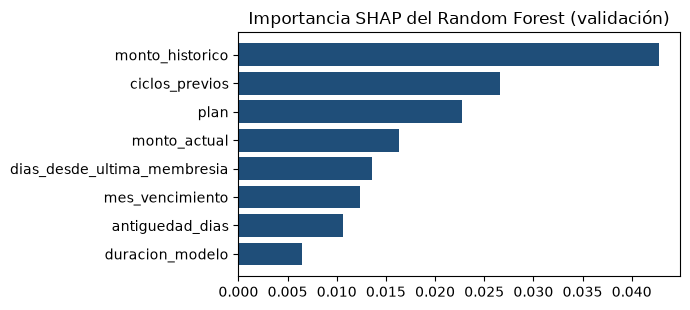

In [13]:
def permutacion(modelo):
    r = permutation_importance(modelo, X_validation, y_validation, scoring="average_precision",
                               n_repeats=10, random_state=SEMILLA)
    return pd.Series(r.importances_mean, index=VARIABLES_MODELO)
importancia_permutacion = pd.DataFrame({f"permutación {n}": permutacion(m) for n, m in modelos.items()})
importancia_permutacion.index.name = "variable"

# Coeficientes de la Regresión Logística (variables estandarizadas; las categóricas, una columna por categoría)
rl = modelos["Regresión Logística"]
coeficientes_rl = (pd.Series(rl.named_steps["modelo"].coef_[0], index=rl.named_steps["preparacion"].get_feature_names_out())
                   .sort_values(key=abs, ascending=False).rename("coeficiente"))
print("Coeficientes de la Regresión Logística (los 10 de mayor magnitud):")
display(coeficientes_rl.head(10).round(3).to_frame())

def explicar_shap(modelo, X):
    # SHAP exacto del bosque sobre la matriz preparada; las columnas one-hot se suman a su variable original
    prep, bosque = modelo.named_steps["preparacion"], modelo.named_steps["modelo"]
    matriz = prep.transform(X)
    matriz = np.asarray(matriz.toarray() if hasattr(matriz, "toarray") else matriz, dtype=np.float64)
    explicador = shap.TreeExplainer(bosque)
    valores = explicador.shap_values(matriz)
    valores = np.stack(valores, axis=-1) if isinstance(valores, list) else np.asarray(valores)
    por_columna = valores[:, :, 1]                               # clase 1 = "no renovó"
    base = float(np.atleast_1d(explicador.expected_value)[1])
    destino = []                                                 # variable original de cada columna
    for nombre, transformador, columnas in prep.transformers_:
        if nombre == "numericas":
            destino += list(columnas)
        elif nombre == "categoricas":
            for col, cats in zip(columnas, transformador.named_steps["one_hot"].categories_):
                destino += [col] * len(cats)
    agregado = np.zeros((matriz.shape[0], len(VARIABLES_MODELO)))
    for j, v in enumerate(destino):                              # suma en el mismo orden que la app
        agregado[:, VARIABLES_MODELO.index(v)] += por_columna[:, j]
    error = float(np.max(np.abs(base + agregado.sum(axis=1) - modelo.predict_proba(X)[:, 1])))
    return base, pd.DataFrame(agregado, index=X.index, columns=VARIABLES_MODELO), error

base_shap, shap_validacion, error_shap = explicar_shap(modelos[MODELO_PRODUCTO], X_validation)
print(f"Valor base SHAP: {base_shap:.4f} | error de aditividad: {error_shap:.1e}")
importancias = importancia_permutacion.join(shap_validacion.abs().mean().rename(f"SHAP medio absoluto {MODELO_PRODUCTO}"))
display(importancias.sort_values(f"SHAP medio absoluto {MODELO_PRODUCTO}", ascending=False).round(4))

fig, ax = plt.subplots(figsize=(7, 3.2))
s = importancias[f"SHAP medio absoluto {MODELO_PRODUCTO}"].sort_values()
ax.barh(s.index, s.values, color="#1F4E79")
ax.set_title(f"Importancia SHAP del {MODELO_PRODUCTO} (validación)")
plt.tight_layout(); plt.show()

## Parte 10 · El producto: lista de septiembre 2026 (igual que la app)
- **Modelo operativo:** el modelo del producto (Random Forest, el de la app) reentrenado con **todas** las membresías con resultado (1.564, incluidos los márgenes), con sus propias medianas. Es el que usa la app.
- **Cartera:** membresías que vencen en los 30 días siguientes al corte, sin pases diarios ni duraciones imposibles. Se excluye a quien ya renovó.
- **Nivel:** ALTO ≥ 0,70, MEDIO ≥ 0,50, BAJO < 0,50. **Motivos:** hasta 3 variables que suben el riesgo más de 0,005 según SHAP (nunca el mes de vencimiento).

In [14]:
# 1) Modelo operativo
mediana_por_plan_op, mediana_general_op = calcular_medianas(analitico)
analitico_operativo = completar_monto_y_duracion(analitico, mediana_por_plan_op, mediana_general_op)
modelo_operativo = clone(modelos[MODELO_PRODUCTO]).fit(analitico_operativo[VARIABLES_MODELO], analitico_operativo["no_renovo"])

# 2) Cartera a vencer en el horizonte
FECHA_GENERACION, HORIZONTE_DIAS = fecha_corte, 30
cartera = datos.loc[(datos["fecha_fin"] > FECHA_GENERACION)
                    & (datos["fecha_fin"] <= FECHA_GENERACION + pd.Timedelta(days=HORIZONTE_DIAS))
                    & datos["plan"].ne("DIARIO")
                    & ~((datos["duracion_dias"] <= DURACION_MIN) | (datos["duracion_dias"] > DURACION_MAX))].copy()

def ya_renovo(fila):                           # ya registró una membresía posterior: no hace falta llamarlo
    h = actividades_por_socio.get(fila["socio_id"])
    return h is not None and bool(((h.index != fila.name) & (h["fecha_actividad"] > fila["fecha_actividad"])).any())

cartera["ya_renovo"] = cartera.apply(ya_renovo, axis=1)
cartera = cartera.join(calcular_historial(cartera, modelables))
cartera = completar_monto_y_duracion(cartera, mediana_por_plan_op, mediana_general_op)
a_priorizar = cartera.loc[~cartera["ya_renovo"]].copy()

# 3) Score, nivel y motivos
NOMBRE_VARIABLE = {"ciclos_previos": "Membresías previas", "antiguedad_dias": "Antigüedad (días)",
                   "duracion_modelo": "Duración del plan (días)", "monto_actual": "Monto actual (USD)",
                   "monto_historico": "Monto histórico (USD)",
                   "dias_desde_ultima_membresia": "Días desde la membresía anterior", "plan": "Plan"}

def nivel_riesgo(p):
    return "ALTO" if p >= UMBRAL_ALTO else ("MEDIO" if p >= UMBRAL_MEDIO else "BAJO")

def es(x, d=2, signo=False):                   # número con coma decimal: 0,05
    t = f"{x:{'+' if signo else ''},.{d}f}"
    return t.replace(",", "X").replace(".", ",").replace("X", ".")

def motivos(modelo, X):
    _, aportes, _ = explicar_shap(modelo, X)
    textos = []
    for idx, fila in aportes.iterrows():
        elegidas = sorted([v for v in NOMBRE_VARIABLE if fila[v] > 0.005], key=lambda v: fila[v], reverse=True)[:3]
        partes = []
        for v in elegidas:
            valor = X.at[idx, v]
            valor = "sin dato" if pd.isna(valor) else (f"{valor:,.0f}".replace(",", ".") if v in VARIABLES_NUMERICAS else str(valor))
            partes.append(f"{NOMBRE_VARIABLE[v]}: {valor} ({es(fila[v], 2, True)})")
        textos.append("; ".join(partes) if partes else "Sin factores de riesgo destacados")
    return pd.Series(textos, index=X.index)

a_priorizar["probabilidad"] = modelo_operativo.predict_proba(a_priorizar[VARIABLES_MODELO])[:, 1]
a_priorizar["nivel_riesgo"] = a_priorizar["probabilidad"].apply(nivel_riesgo)
a_priorizar["motivos"] = motivos(modelo_operativo, a_priorizar[VARIABLES_MODELO])
a_priorizar["codigo"] = a_priorizar["socio_id"].apply(codigo_socio)

lista = (a_priorizar.sort_values("probabilidad", ascending=False)
         .drop_duplicates("socio_id", keep="first").copy())     # una fila por socio (la de mayor riesgo)
lista["prioridad"] = np.arange(1, len(lista) + 1)
lista["dentro_de_capacidad"] = np.where(lista["prioridad"] <= TOP_K, "Sí", "No")
print(f"Lista generada con datos al {FECHA_GENERACION.date()}: {len(lista)} socios ->",
      lista["nivel_riesgo"].value_counts().to_dict())
display(lista[["prioridad", "codigo", "fecha_fin", "plan", "probabilidad", "nivel_riesgo", "motivos",
               "dentro_de_capacidad"]].head(TOP_K).round(3))

# Comparación informativa: lista que daría la Regresión Logística (modelo seleccionado) con los mismos datos
modelo_operativo_rl = clone(modelos["Regresión Logística"]).fit(analitico_operativo[VARIABLES_MODELO], analitico_operativo["no_renovo"])
a_priorizar["probabilidad_rl"] = modelo_operativo_rl.predict_proba(a_priorizar[VARIABLES_MODELO])[:, 1]
top_rl = set(a_priorizar.sort_values("probabilidad_rl", ascending=False).drop_duplicates("socio_id")["socio_id"].head(TOP_K))
coinciden_top = len(top_rl & set(lista["socio_id"].head(TOP_K)))
print(f"Socios del top {TOP_K} de septiembre que coinciden entre el Random Forest (app) y la Regresión Logística: {coinciden_top} de {TOP_K}")


Lista generada con datos al 2026-08-31: 57 socios -> {'MEDIO': 39, 'BAJO': 16, 'ALTO': 2}


,prioridad,codigo,fecha_fin,plan,probabilidad,nivel_riesgo,motivos,dentro_de_capacidad
2774,1,MTB-5EA647BF,2026-09-01,ANUAL,0.710,ALTO,"Monto actual (USD): 225 (+0,04); Monto histórico (USD): 0 (+0,04); Plan: ANUAL (+0,04)",Sí
2775,2,MTB-15108E84,2026-09-01,ANUAL,0.710,ALTO,"Monto actual (USD): 225 (+0,04); Monto histórico (USD): 0 (+0,04); Plan: ANUAL (+0,04)",Sí
7274,3,MTB-CB93D1B5,2026-09-13,OTRO,0.697,MEDIO,"Plan: OTRO (+0,06); Monto histórico (USD): 0 (+0,03); Monto actual (USD): 70 (+0,03)",Sí
7075,4,MTB-C6952D4A,2026-09-01,OTRO,0.692,MEDIO,"Plan: OTRO (+0,06); Monto histórico (USD): 0 (+0,03); Membresías previas: 0 (+0,02)",Sí
7076,5,MTB-9E6B1153,2026-09-01,OTRO,0.692,MEDIO,"Plan: OTRO (+0,06); Monto histórico (USD): 0 (+0,03); Membresías previas: 0 (+0,02)",Sí
7160,6,MTB-B662D60D,2026-09-06,OTRO,0.692,MEDIO,"Plan: OTRO (+0,06); Monto histórico (USD): 0 (+0,03); Membresías previas: 0 (+0,02)",Sí
3768,7,MTB-EE3FE1EF,2026-09-25,ANUAL,0.675,MEDIO,"Monto histórico (USD): 0 (+0,04); Plan: ANUAL (+0,04); Membresías previas: 0 (+0,03)",Sí
6212,8,MTB-5DB45CC4,2026-09-09,TRIMESTRAL,0.656,MEDIO,"Monto histórico (USD): 0 (+0,03); Plan: TRIMESTRAL (+0,03); Membresías previas: 0 (+0,03)",Sí
6048,9,MTB-CF8CFF06,2026-09-05,TRIMESTRAL,0.644,MEDIO,"Monto histórico (USD): 0 (+0,03); Plan: TRIMESTRAL (+0,03); Membresías previas: 0 (+0,02)",Sí
6522,10,MTB-C0775C0B,2026-09-26,TRIMESTRAL,0.644,MEDIO,"Monto histórico (USD): 0 (+0,03); Plan: TRIMESTRAL (+0,03); Membresías previas: 0 (+0,02)",Sí


Socios del top 25 de septiembre que coinciden entre el Random Forest (app) y la Regresión Logística: 23 de 25


## Parte 11 · Controles: ¿este notebook da lo mismo que el original y que la app?
Los valores esperados son los de la **versión congelada v2** (2026-11-02). Las cifras de datos, anti-fuga y lista de septiembre deben coincidir además con la app (`Backend/scripts/verificar_lista.py`, que lee las salidas de la Parte 13) y con `MVP.ipynb`. Si algún control falla, revisar los datos o el código antes de usar los resultados; **nunca** cambiar los valores esperados para que coincidan sin documentar el motivo.

In [15]:
registro_controles = []
def control(descripcion, obtenido, esperado):
    ok = obtenido == esperado
    registro_controles.append({"control": descripcion, "obtenido": str(obtenido), "esperado": str(esperado), "ok": bool(ok)})
    print(f"{'OK  ' if ok else 'FALLA'} {descripcion}: obtenido {obtenido} | esperado {esperado}")
    return ok

pr = comparacion_prueba.loc[modelo_seleccionado_nombre]   # modelo que elige la regla
pa = comparacion_prueba.loc[modelo_adoptado_nombre]       # modelo adoptado (el de la app)
resultados_control = [
    control("Registros con identidad", len(datos), 2748),
    control("Socios distintos", datos["socio_id"].nunique(), 1410),
    control("Membresías evaluables", len(analitico), 1564),
    control("No renovaron", int(analitico["no_renovo"].sum()), 1098),
    control("Entrenamiento / validación / prueba", (len(train), len(validation), len(test)), (721, 180, 277)),
    control("Prueba anti-fuga con corte T−30", fuga_con_corte, 0),
    control("Cronología: cada etiqueta se conoce antes de la siguiente predicción", bool(cronologia["Cumple"].all()), True),
    control("Modelo adoptado", modelo_adoptado_nombre, "Random Forest"),
    control("Umbral del modelo adoptado", umbral_adoptado, 0.32),
    control("PR-AUC en prueba del modelo adoptado", round(pa["PR-AUC"], 4), 0.7869),
    control("Precisión@25 en prueba del modelo adoptado", round(pa[f"Precisión@{TOP_K}"], 2), 0.76),
    control("Matriz de confusión del modelo adoptado (VN, FP, FN, VP)", tuple(int(v) for v in matriz.to_numpy().ravel()), (5, 87, 3, 182)),
    control("Modelo que elige la regla (se informa la desviación)", modelo_seleccionado_nombre, "Regresión Logística"),
    control("PR-AUC en prueba del modelo de la regla", round(pr["PR-AUC"], 4), 0.8197),
    control("Socios en la lista de septiembre", len(lista), 57),
    control("Niveles ALTO / MEDIO / BAJO", tuple(int((lista["nivel_riesgo"] == n).sum()) for n in ("ALTO", "MEDIO", "BAJO")), (2, 39, 16)),
]

# Comparación fila a fila con la lista que exportó el notebook original (si el archivo existe)
ruta_original = Path("..") / "salidas" / "mvp" / "lista_operativa_2026-09_top25.csv"
if ruta_original.is_file():
    original = pd.read_csv(ruta_original)
    propia = lista.head(len(original))
    iguales = (np.allclose(original["probabilidad"].to_numpy(), propia["probabilidad"].round(3).to_numpy(), atol=1e-9)
               and list(original["nivel_riesgo"]) == list(propia["nivel_riesgo"])
               and list(original["plan"]) == list(propia["plan"])
               and list(original["factores principales"]) == list(propia["motivos"]))
    resultados_control.append(control("Top 25 de septiembre igual al de MVP.ipynb (probabilidad, nivel, plan y motivos)", iguales, True))
print("\nTODOS LOS CONTROLES OK" if all(resultados_control) else "\nHAY CONTROLES QUE FALLAN: revisar antes de usar")

OK   Registros con identidad: obtenido 2748 | esperado 2748
OK   Socios distintos: obtenido 1410 | esperado 1410
OK   Membresías evaluables: obtenido 1564 | esperado 1564
OK   No renovaron: obtenido 1098 | esperado 1098
OK   Entrenamiento / validación / prueba: obtenido (721, 180, 277) | esperado (721, 180, 277)
OK   Prueba anti-fuga con corte T−30: obtenido 0 | esperado 0
OK   Cronología: cada etiqueta se conoce antes de la siguiente predicción: obtenido True | esperado True
OK   Modelo adoptado: obtenido Random Forest | esperado Random Forest
OK   Umbral del modelo adoptado: obtenido 0.32 | esperado 0.32
OK   PR-AUC en prueba del modelo adoptado: obtenido 0.7869 | esperado 0.7869
OK   Precisión@25 en prueba del modelo adoptado: obtenido 0.76 | esperado 0.76
OK   Matriz de confusión del modelo adoptado (VN, FP, FN, VP): obtenido (5, 87, 3, 182) | esperado (5, 87, 3, 182)
OK   Modelo que elige la regla (se informa la desviación): obtenido Regresión Logística | esperado Regresión Logíst

## Parte 12 · Cifras para el informe
Todas las cifras que el informe final cita salen de esta ejecución. Aquí se reúnen en un solo lugar: tablas de validación y prueba, uso operativo con el umbral, grupos con el top 25 por mes (Tabla 11), SHAP y medianas. La Parte 13 las guarda en archivos.


In [16]:
COLUMNAS_INFORME = ["PR-AUC", f"Precisión@{TOP_K}", f"Lift@{TOP_K}", "ROC-AUC", "F1", "Brier",
                    "Especificidad", "Recall", "Accuracy", "Umbral"]
print("Tabla 7 · Validación (elige el modelo)"); display(comparacion_validacion[COLUMNAS_INFORME].round(3))
print("Tabla 9 · Prueba (comprobación final)");  display(comparacion_prueba[COLUMNAS_INFORME].round(3))

# Uso operativo en prueba con el umbral de cada modelo elegido en validación
y_np = np.asarray(y_test)
def uso_en_prueba(nombre):
    p = proba_test[nombre]
    vn, fp, fn, vp = confusion_matrix(y_np, (p >= umbrales[nombre]).astype(int), labels=[0, 1]).ravel()
    return {"Umbral": umbrales[nombre], "Marcados en riesgo con el umbral": int(vp + fp),
            "No renovaron y no fueron marcados (FN)": int(fn), "Renovaron y fueron marcados (FP)": int(fp),
            f"Aciertos en el top {TOP_K}": int(y_np[np.argsort(p)[::-1][:TOP_K]].sum()),
            f"Aciertos esperados al azar en el top {TOP_K}": round(TOP_K * y_np.mean(), 1)}
uso_operativo = pd.DataFrame({n: uso_en_prueba(n) for n in modelos})
print(f"Uso operativo en prueba ({len(y_np)} membresías, {test['socio_id'].nunique()} socios)"); display(uso_operativo)

# Tabla 11 · grupos con el top 25 de cada mes (VP/FP/FN/VN) y FN que quedan fuera por capacidad
def grupos_top_por_mes(conjunto, p):
    d = conjunto[["fecha_fin", "no_renovo"]].copy()
    d["p"], d["mes"], d["en_top"] = p, d["fecha_fin"].dt.to_period("M"), False
    for _, g in d.groupby("mes"):
        d.loc[g.sort_values("p", ascending=False, kind="mergesort").index[:TOP_K], "en_top"] = True
    nr = d["no_renovo"].eq(1)
    return {"VP (señalados que no renovaron)": int((d["en_top"] & nr).sum()),
            "FP (señalados que sí renovaron)": int((d["en_top"] & ~nr).sum()),
            "FN (no señalados que no renovaron)": int((~d["en_top"] & nr).sum()),
            "VN (no señalados que renovaron)": int((~d["en_top"] & ~nr).sum()),
            "FN inevitables por capacidad": int(sum(max(0, int(g["no_renovo"].sum()) - TOP_K) for _, g in d.groupby("mes"))),
            "Meses": d["mes"].nunique()}
tabla_11 = pd.DataFrame({f"{n} · {conjunto} ({len(d)})": grupos_top_por_mes(d, p[n])
                         for n in modelos
                         for conjunto, d, p in [("Validación", validation, proba_validacion), ("Prueba", test, proba_test)]}).T
print("Tabla 11 · Top 25 por mes"); display(tabla_11)

# SHAP: valor base, aportes medios y estabilidad entre períodos
_, shap_prueba, error_shap_prueba = explicar_shap(modelos[MODELO_PRODUCTO], X_test)
base_operativo, _, _ = explicar_shap(modelo_operativo, a_priorizar[VARIABLES_MODELO])
shap_medio = pd.DataFrame({"validación": shap_validacion.abs().mean(), "prueba": shap_prueba.abs().mean()})
correlacion_rangos = float(shap_medio["validación"].rank().corr(shap_medio["prueba"].rank()))
correlacion_historial = float(analitico["monto_historico"].corr(analitico["ciclos_previos"]))
print(f"SHAP del {MODELO_PRODUCTO} · valor base modelo evaluado: {base_shap:.3f} | modelo operativo: {base_operativo:.3f} | "
      f"error de aditividad en prueba: {error_shap_prueba:.1e}")
display(shap_medio.sort_values("validación", ascending=False).round(3))
print(f"Correlación de rangos SHAP validación–prueba: {correlacion_rangos:.2f} | "
      f"correlación total pagado–membresías previas: {correlacion_historial:.2f}")

# Medianas de monto por plan: solo entrenamiento (evaluación) frente a todos los casos (modelo operativo)
medianas = pd.DataFrame({"entrenamiento": mediana_por_plan, "modelo operativo": mediana_por_plan_op}).round(2)
display(medianas)

cifras_informe = {
    "particiones": resumen_particiones.reset_index().astype(str).to_dict("records"),
    "modelo_seleccionado": modelo_seleccionado_nombre, "umbral": umbral_seleccionado, "seleccion_formal": seleccion_formal,
    "modelo_adoptado": modelo_adoptado_nombre, "umbral_adoptado": umbral_adoptado,
    "desviacion_regla": desviacion_regla, "diferencia_pr_auc_validacion_regla_menos_adoptado": round(float(diferencia_pr_auc), 3),
    "coinciden_top25_rf_rl": coinciden_top,
    "uso_operativo": uso_operativo.astype(float).round(3).to_dict(),
    "shap_base_evaluado": round(base_shap, 3), "shap_base_operativo": round(base_operativo, 3),
    "correlacion_rangos_shap": round(correlacion_rangos, 2), "correlacion_historial": round(correlacion_historial, 2),
    "lista_septiembre": {"socios": len(lista), **lista["nivel_riesgo"].value_counts().to_dict()},
}


Tabla 7 · Validación (elige el modelo)


,PR-AUC,Precisión@25,Lift@25,ROC-AUC,F1,Brier,Especificidad,Recall,Accuracy,Umbral
Sin modelo (piso),0.633,0.633,1.000,0.500,0.776,0.247,0.000,1.000,0.633,0.50
Regresión Logística,0.724,0.640,1.011,0.621,0.783,0.240,0.136,0.965,0.661,0.21
Random Forest,0.707,0.760,1.200,0.624,0.780,0.243,0.076,0.982,0.650,0.32


Tabla 9 · Prueba (comprobación final)


,PR-AUC,Precisión@25,Lift@25,ROC-AUC,F1,Brier,Especificidad,Recall,Accuracy,Umbral
Sin modelo (piso),0.668,0.668,1.000,0.50,0.801,0.229,0.000,1.000,0.668,0.50
Regresión Logística,0.820,1.000,1.497,0.68,0.800,0.236,0.239,0.919,0.693,0.21
Random Forest,0.787,0.760,1.138,0.70,0.802,0.236,0.054,0.984,0.675,0.32


Uso operativo en prueba (277 membresías, 215 socios)


,Regresión Logística,Random Forest
Umbral,0.21,0.32
Marcados en riesgo con el umbral,240.00,269.00
No renovaron y no fueron marcados (FN),15.00,3.00
Renovaron y fueron marcados (FP),70.00,87.00
Aciertos en el top 25,25.00,19.00
Aciertos esperados al azar en el top 25,16.70,16.70


... (2 outputs left out)

SHAP del Random Forest · valor base modelo evaluado: 0.499 | modelo operativo: 0.500 | error de aditividad en prueba: 2.3e-15


,validación,prueba
monto_historico,0.043,0.042
ciclos_previos,0.027,0.027
plan,0.023,0.023
monto_actual,0.016,0.018
dias_desde_ultima_membresia,0.014,0.015
mes_vencimiento,0.012,0.012
antiguedad_dias,0.011,0.007
duracion_modelo,0.006,0.007


Correlación de rangos SHAP validación–prueba: 1.00 | correlación total pagado–membresías previas: 0.93


,entrenamiento,modelo operativo
plan,,
ANUAL,224.52,237.5
MENSUAL,37.50,39.0
OTRO,65.00,65.0
SEMESTRAL,175.00,175.0
TRIMESTRAL,90.00,90.0


## Parte 13 · Guardar tablas, modelos y versiones
Se guardan en `salidas/prototipo_final/` (carpeta fuera de git porque `salidas/` también contiene datos personales). Estos archivos solo tienen cifras agregadas y los modelos, sin nombres, cédulas ni códigos de socio.


In [17]:
CARPETA_SALIDA = Path("..") / "salidas" / "prototipo_final"
CARPETA_SALIDA.mkdir(parents=True, exist_ok=True)
tablas = {"particiones": resumen_particiones, "cronologia": cronologia,
          "comparacion_validacion": comparacion_validacion, "comparacion_prueba": comparacion_prueba,
          "bootstrap_validacion": bootstrap_validacion, "bootstrap_prueba": bootstrap_prueba,
          "importancias_validacion": importancias, "shap_medio": shap_medio, "medianas_por_plan": medianas,
          "matriz_confusion_prueba": matriz, "matriz_confusion_prueba_regla": matriz_regla, "tabla_11_top25_por_mes": tabla_11,
          "uso_operativo_prueba": uso_operativo, "coeficientes_regresion_logistica": coeficientes_rl.to_frame(), "controles": pd.DataFrame(registro_controles)}
for nombre, tabla in tablas.items():
    tabla.to_csv(CARPETA_SALIDA / f"{nombre}.csv", encoding="utf-8")

joblib.dump({"modelo": modelo_adoptado, "nombre_modelo": f"{modelo_adoptado_nombre} (adoptado)", "umbral": umbral_adoptado,
             "variables_modelo": VARIABLES_MODELO, "fin_entrenamiento": str(FIN_ENTRENAMIENTO.date())},
            CARPETA_SALIDA / "modelo_evaluado.joblib")
joblib.dump({"modelo": modelo_seleccionado, "nombre_modelo": f"{modelo_seleccionado_nombre} (elegido por la regla)",
             "umbral": umbral_seleccionado, "variables_modelo": VARIABLES_MODELO,
             "fin_entrenamiento": str(FIN_ENTRENAMIENTO.date())},
            CARPETA_SALIDA / "modelo_regla_evaluado.joblib")
joblib.dump({"modelo": modelo_operativo, "nombre_modelo": f"{MODELO_PRODUCTO} (operativo, el de la app)",
             "variables_modelo": VARIABLES_MODELO, "fecha_corte_datos": str(fecha_corte.date())},
            CARPETA_SALIDA / "modelo_operativo.joblib")

# Referencia para Backend/scripts/verificar_lista.py: mismo formato que las salidas de MVP.ipynb.
# La lista lleva códigos seudónimos (HMAC), nunca nombres ni cédulas; salidas/ está fuera de git.
referencia_factores = {v: float(X_train[v].median()) for v in VARIABLES_NUMERICAS}
referencia_factores.update({v: str(X_train[v].mode().iloc[0]) for v in VARIABLES_CATEGORICAS})
fin_horizonte = FECHA_GENERACION + pd.Timedelta(days=HORIZONTE_DIAS)
parametros_operativo = {
    "semilla": SEMILLA, "modelo": MODELO_ADOPTADO,
    "variables_numericas": VARIABLES_NUMERICAS, "variables_categoricas": VARIABLES_CATEGORICAS,
    "hiperparametros_random_forest": HIPERPARAMETROS_RF,
    "ciclos_entrenamiento_operativo": len(analitico_operativo),
    "medianas_monto_operativo": {"por_plan": {k: float(v) for k, v in mediana_por_plan_op.items()},
                                 "general": float(mediana_general_op)},
    "medianas_monto_evaluacion_entrenamiento": {"por_plan": {k: float(v) for k, v in mediana_por_plan.items()},
                                                "general": float(mediana_general)},
    "referencia_factores": referencia_factores,
    "referencia_factores_periodo": f"vencimientos del {train['fecha_fin'].min():%Y-%m-%d} al {train['fecha_fin'].max():%Y-%m-%d} (conjunto de entrenamiento)",
    "metodo_factores": "shap",
    "cartera_septiembre": {
        f"Ciclos que vencen entre el {FECHA_GENERACION + pd.Timedelta(days=1):%d-%m-%Y} y el {fin_horizonte:%d-%m-%Y}": len(cartera),
        "ya registraron una membresía posterior (renovación anticipada)": int(cartera["ya_renovo"].sum()),
        "Ciclos a priorizar": len(a_priorizar), "Socios distintos a priorizar": int(a_priorizar["socio_id"].nunique())},
    "fecha_corte_datos": str(fecha_corte.date()),
}
(CARPETA_SALIDA / "parametros_modelo_operativo.json").write_text(
    json.dumps(parametros_operativo, ensure_ascii=False, indent=2), encoding="utf-8")
with pd.ExcelWriter(CARPETA_SALIDA / "lista_operativa_2026-09.xlsx", engine="openpyxl") as escritor:
    (lista.rename(columns={"codigo": "socio_anonimo", "motivos": "factores principales"})
          [["prioridad", "socio_anonimo", "fecha_fin", "plan", "probabilidad", "nivel_riesgo", "factores principales", "dentro_de_capacidad"]]
          .to_excel(escritor, sheet_name="cartera_completa", index=False))

ejecucion = {"fecha_ejecucion": datetime.now().isoformat(timespec="seconds"), "python": sys.version.split()[0],
             "librerias": {"pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__,
                           "shap": shap.__version__, "joblib": joblib.__version__},
             "huellas_excel_sha256_16": HUELLAS,
             "huellas_modelos_sha256_16": {p.name: huella(p) for p in sorted(CARPETA_SALIDA.glob("*.joblib"))},
             "todos_los_controles_ok": all(resultados_control), "cifras_informe": cifras_informe}
(CARPETA_SALIDA / "ejecucion.json").write_text(json.dumps(ejecucion, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print("Archivos guardados en", CARPETA_SALIDA.resolve().relative_to(Path("..").resolve()), ":")
print(sorted(p.name for p in CARPETA_SALIDA.iterdir()))
print("Huellas de los modelos:", ejecucion["huellas_modelos_sha256_16"])


Archivos guardados en salidas/prototipo_final :
['bootstrap_prueba.csv', 'bootstrap_validacion.csv', 'coeficientes_regresion_logistica.csv', 'comparacion_prueba.csv', 'comparacion_validacion.csv', 'controles.csv', 'cronologia.csv', 'ejecucion.json', 'importancias_validacion.csv', 'lista_operativa_2026-09.xlsx', 'matriz_confusion_prueba.csv', 'matriz_confusion_prueba_regla.csv', 'medianas_por_plan.csv', 'modelo_evaluado.joblib', 'modelo_operativo.joblib', 'modelo_regla_evaluado.joblib', 'parametros_modelo_operativo.json', 'particiones.csv', 'shap_medio.csv', 'tabla_11_top25_por_mes.csv', 'uso_operativo_prueba.csv']
Huellas de los modelos: {'modelo_evaluado.joblib': 'fdf111beb6f54668', 'modelo_operativo.joblib': 'bfdfe0c14e9edcb8', 'modelo_regla_evaluado.joblib': 'ccb1f380e3db9e87'}


## Objetos disponibles para trabajar
Después de ejecutar todo, quedan en memoria y listos para las pruebas:

| Objeto | Qué es |
|---|---|
| `datos` | Todas las filas limpias, con estado y etiqueta |
| `modelables`, `analitico` | Membresías con variables en T−30 (todas / solo con resultado) |
| `train`, `validation`, `test` y sus `X_` / `y_` | Los tres conjuntos por fecha |
| `modelo_adoptado`, `umbral_adoptado` | Random Forest evaluado, el modelo adoptado (entrenado solo con vencimientos hasta el 31-10-2025) |
| `modelo_seleccionado`, `umbral_seleccionado` | Modelo que elige la regla (Regresión Logística); `desviacion_regla` indica si difiere del adoptado |
| `cronologia`, `resumen_particiones` | Control NC1 y tamaño de cada conjunto |
| `bootstrap_validacion`, `bootstrap_prueba` | Intervalos por socio (Tabla 10 del informe) |
| `cifras_informe` | Cifras de la Parte 12 para actualizar el informe |
| `modelo_operativo` | Random Forest con todos los datos: **el que usa la app** |
| `modelo_operativo_rl` | Regresión Logística con todos los datos (solo comparación) |
| `coeficientes_rl` | Coeficientes de la Regresión Logística |
| `mediana_por_plan`, `mediana_general` | Medianas de monto de entrenamiento |
| `explicar_shap(modelo, X)`, `motivos(modelo, X)`, `nivel_riesgo(p)` | Explicación, motivos y nivel |
| `lista` | Lista de septiembre con prioridad, nivel y motivos |
| `codigo_socio(socio_id)` | Código seudónimo (HMAC) para mostrar socios sin datos personales |